# **HW1 – PyTorch Lightning, model monitoring, hyperparameter optimization – CIFAR-10**

This notebook **does not train any models** – it loads the results produced by the scripts in `src/` (`./run_all.sh`) and performs the analysis required by the assignment:

1. Task and data, choice of metrics
2. Baseline – train/val curves, does the model learn
3. Change introduced based on the curves (`manual_fix`)
4. Hyperparameter optimization: search space, trial results, pruning, parameter importance
5. Comparison of the baseline vs the best configuration (≥ 3% criterion)
6. Error analysis of the best model
7. Monitoring in MLflow

In [1]:
from pathlib import Path
import json, sys, warnings

import yaml
import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import CLASSES, _load_batches
from src.config import RUNS_DIR, RESULTS_DIR, MLFLOW_URI, DATA_DIR

from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances, plot_intermediate_values, plot_slice

import mlflow

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

In [2]:
def load_run(name):
    d = RUNS_DIR / name
    m = pd.read_csv(d / "metrics.csv")
    per_epoch = m.groupby("epoch").first()   # each metric logged in a separate row -> merge per epoch
    per_epoch = per_epoch.dropna(subset=["train_loss"])  # drop the row from the final trainer.validate()
    summary = json.loads((d / "summary.json").read_text())
    return per_epoch, summary

runs = {n: load_run(n) for n in ["baseline", "manual_fix", "best"] if (RUNS_DIR / n / "summary.json").exists()}
print("Available runs:", list(runs))

Available runs: ['baseline', 'manual_fix', 'best']


## **1. Task and data**

### **Task** 
Classification of 32×32 RGB images into 10 classes (CIFAR-10).

### **Why it is not too easy** 
A small network without tuning reaches ~75–85%, so there is real room for improvement through HPO (unlike MNIST).

### **Split** 
45,000 train / 5,000 val (fixed random split of the official train set) / 10,000 test (official). Split of training data into training and validation datasets is fixed so that comparison between different models is fair and doesn't depend on lucky split.

### **Implementation** 
Custom classes – `CIFAR10Dataset` (read the raw pickle files) and `CIFAR10DataModule` (download, split, on-GPU augmentation in `on_after_batch_transfer`) are implemented in `src/data.py`. `CIFAR10Classifier` (LightningModule, small ResNet) is located in  `src/model.py`.

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train(all 50k),5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


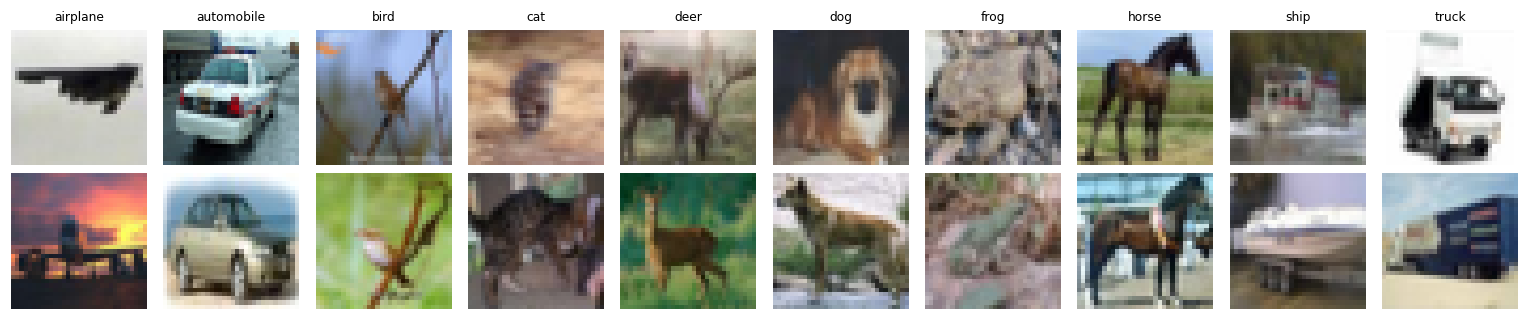

In [3]:
x_tr, y_tr = _load_batches(DATA_DIR, train=True)
x_te, y_te = _load_batches(DATA_DIR, train=False)
counts = pd.DataFrame({"train(all 50k)": np.bincount(y_tr), "test": np.bincount(y_te)}, index=CLASSES)
display(counts.T)

fig, axes = plt.subplots(2, 10, figsize=(14, 3))
rng = np.random.default_rng(1)
for c in range(10):
    for r in range(2):
        i = rng.choice(np.where(y_tr == c)[0])
        axes[r, c].imshow(x_tr[i].transpose(1, 2, 0)); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.tight_layout()
plt.show()

### **Choice of metrics** 

The classes are perfectly balanced (5,000/1,000 examples each), so accuracy is meaningful. As the main metric (monitored by checkpointing, pruning and Optuna) we nevertheless use **macro-F1 (`val_f1`)** – it is robust to a situation in which the model sacrifices one class (e.g. `cat`) in favour of the others, which accuracy would not reveal. On a balanced dataset macro-F1 ≈ accuracy, so we report both side by side.

## **2. Baseline – does the model learn?**

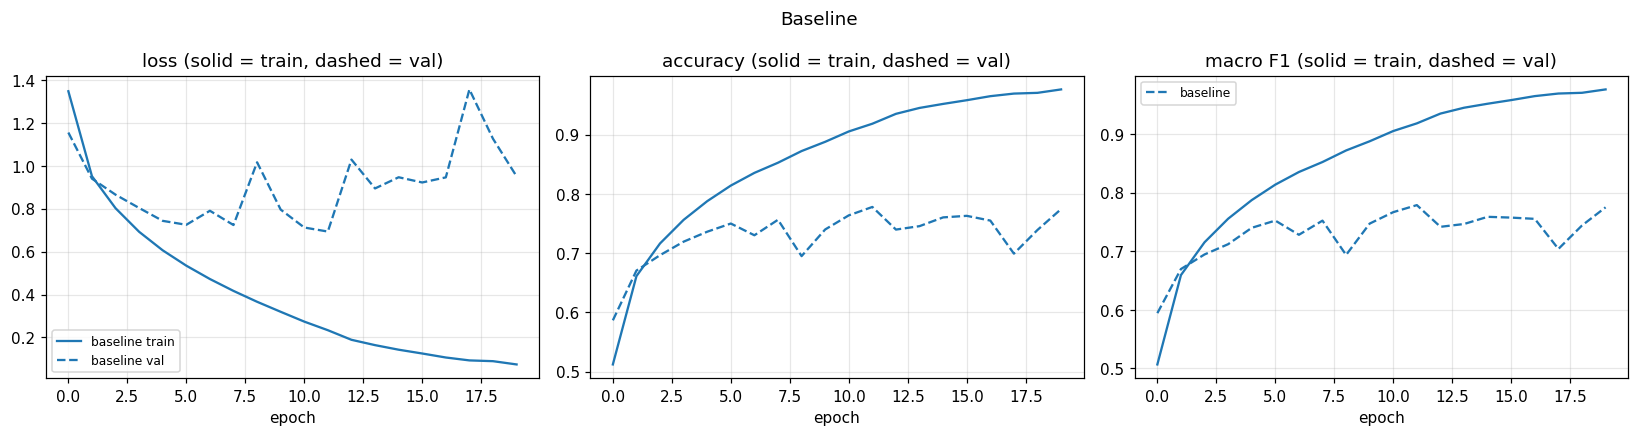

best val_f1 = 0.7788 @ epoch 11
val_loss: min 0.694 @ epoch 11.0, final 0.951
final train_acc - val_acc gap = 0.202


In [4]:
RUN_COLORS = {"baseline": "tab:blue", "manual_fix": "tab:green", "best": "tab:red"}

def plot_curves(names, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for name in names:
        df, _ = runs[name]
        c = RUN_COLORS[name]
        axes[0].plot(df.index, df["train_loss"], "-", color=c, label=f"{name} train")
        axes[0].plot(df.index, df["val_loss"], "--", color=c, label=f"{name} val")
        axes[1].plot(df.index, df["train_acc"], "-", color=c)
        axes[1].plot(df.index, df["val_acc"], "--", color=c, label=name)
        axes[2].plot(df.index, df["train_f1"], "-", color=c)
        axes[2].plot(df.index, df["val_f1"], "--", color=c, label=name)
    for ax, t in zip(axes, ["loss", "accuracy", "macro F1"]):
        ax.set_title(f"{t} (solid = train, dashed = val)"); ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8); axes[2].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_curves(["baseline"], "Baseline")
df, s = runs["baseline"]
print(f"best val_f1 = {s['best_val_f1']:.4f} @ epoch {s['best_epoch']}")
print(f"val_loss: min {df['val_loss'].min():.3f} @ epoch {df['val_loss'].idxmin()}, final {df['val_loss'].iloc[-1]:.3f}")
print(f"final train_acc - val_acc gap = {df['train_acc'].iloc[-1] - df['val_acc'].iloc[-1]:.3f}")

### **Interpretation**
Train and val loss decrease during the first epochs, thus the baseline model learns (val accuracy is far above the 10% of random guessing). However, after a few epochs (from epoch 5 on, where val loss reaches 0.725) training loss decreases further while validation loss started to fluctuate and train/val accuracy gap keeps growing. This behavior can signal potential **overfitting** of the baseline model, i.e. it started to memorise already seen pictures instead of learning from them. This is expected for a baseline without regularisation. Numerically: train loss keeps falling to 0.07 (train accuracy 97.6%), while val loss jumps between 0.69 and 1.36 and ends at 0.95; the final train–val accuracy gap is 20 pp and val macro-F1 plateaus at ~0.75–0.78.

## **3. Change of hyperparameters based on the curves**

Motivated by the overfitting visible in the baseline curves, we made following changes of the hyperparameters:
* **augmentation** (random crop with padding 4 + horizontal flip) – more "diverse" data,
* **weight decay 5e-4** – weight regularisation,
* **cosine LR schedule** – a lower Learning Rate at the end of training stabilises the val loss.

The configuration can be found in `configs/manual_fix.yaml` file.

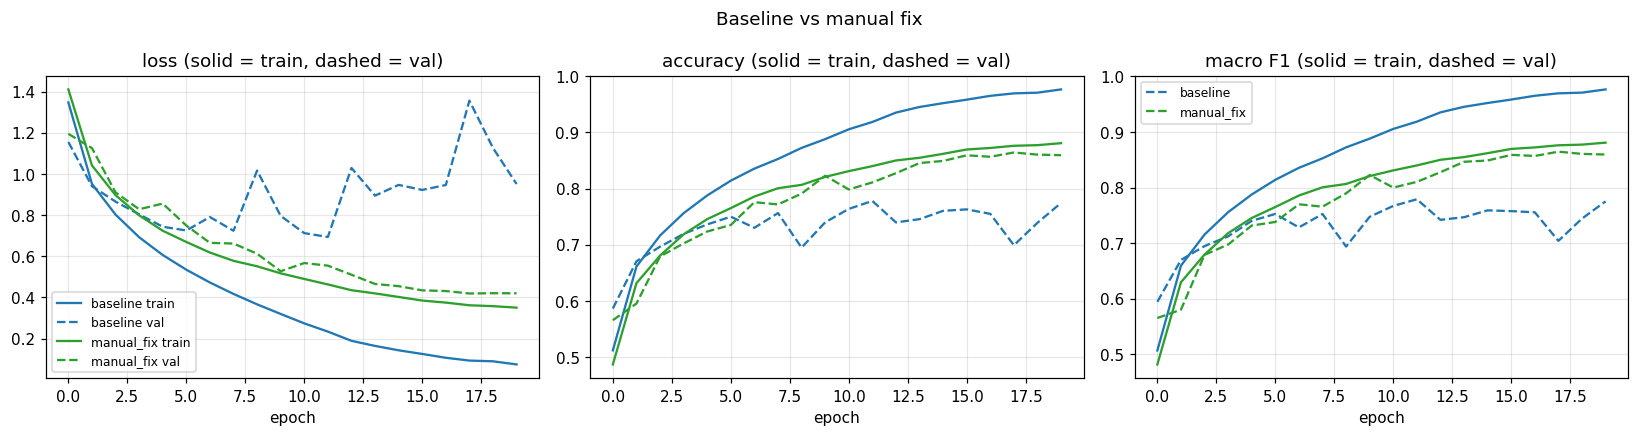

baseline    best val_f1=0.7788  final gap(train-val acc) = +0.202
manual_fix  best val_f1=0.8644  final gap(train-val acc) = +0.021


In [5]:
if "manual_fix" in runs:
    plot_curves(["baseline", "manual_fix"], "Baseline vs manual fix")
    for n in ["baseline", "manual_fix"]:
        df, s = runs[n]
        print(f"{n:11s} best val_f1={s['best_val_f1']:.4f}  final gap(train-val acc) = {df['train_acc'].iloc[-1]-df['val_acc'].iloc[-1]:+.3f}")

## **4. Hyperparameter optimization (Optuna)**

### **Optimization part**

Optimization (`src/optimize.py` file) is performed in a following way:

1. An Optuna study is created (or resumed) in SQLite (`results/optuna.db`) – with direction to maximize.
2. Trial 0 is the baseline configuration (inserted with `enqueue_trial`), so all other trials can be compared with it under the same budget.
3. In every trial the TPE sampler proposes a configuration from the search space below, which is merged with `configs/baseline.yaml`.
4. The configuration is trained for 10 epochs with the same `run_training` function as the main runs; each trial is a separate MLflow run in the `cifar10-optuna` experiment.
5. After every epoch `val_f1` is reported to Optuna; the MedianPruner stops the trial if it is worse than the median of previous trials at the same epoch.
6. The trial's objective is its best `val_f1`. After 30 trials the best parameters are saved to `results/best_params.yaml` and retrained for the full 20 epochs → run `best`.

**Details:**

Configurations are proposed by the multivariate TPE sampler, which models the joint distribution of good and bad
configurations (so it can capture dependencies such as "the right LR depends on the optimizer") instead of treating each
parameter independently. The first 10 trials are sampled randomly to give TPE an initial picture of the search space;
from then on it focuses on promising regions. To keep the search affordable, each trial is trained for only 10 epochs –
half of the final budget – and unpromising trials are stopped early by the MedianPruner, connected to Lightning through
`PyTorchLightningPruningCallback`, which reports `val_f1` after every epoch. The pruner becomes active from the 5th trial
on and only after 3 warm-up epochs, so that a trial is not discarded on the basis of its noisy first epochs. Because the
shortened budget favours configurations that learn quickly, the winning configuration is retrained afterwards with the
full baseline budget of 20 epochs (run `best`), and the enqueued baseline (trial 0) shows what the default configuration
achieves under exactly the same 10-epoch budget. The search space covers the optimizer and its learning rate (with
separate ranges for AdamW and SGD, since their sensible values differ by an order of magnitude), the LR schedule,
regularisation (weight decay, dropout, label smoothing, augmentation), the batch size and the network width:

| parameter | range |
|---|---|
| optimizer | {adamw, sgd (nesterov)} |
| lr | adamw: 1e-4 – 1e-2 (log), sgd: 1e-2 – 3e-1 (log) |
| scheduler | {none, cosine, onecycle} |
| weight_decay | 1e-6 – 1e-2 (log) |
| dropout | 0 – 0.5 |
| label_smoothing | 0 – 0.2 |
| augment | {False, True} |
| batch_size | {64, 128, 256} |
| width | {32, 48, 64} |

In [6]:
study = optuna.load_study(study_name="cifar10_resnet", storage=f"sqlite:///{RESULTS_DIR / 'optuna.db'}")
tdf = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs", "duration"))
tdf.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in tdf.columns]
print(tdf["state"].value_counts().to_string())
# display(tdf.sort_values("value", ascending=False).head(10))

state
PRUNED      21
COMPLETE     9


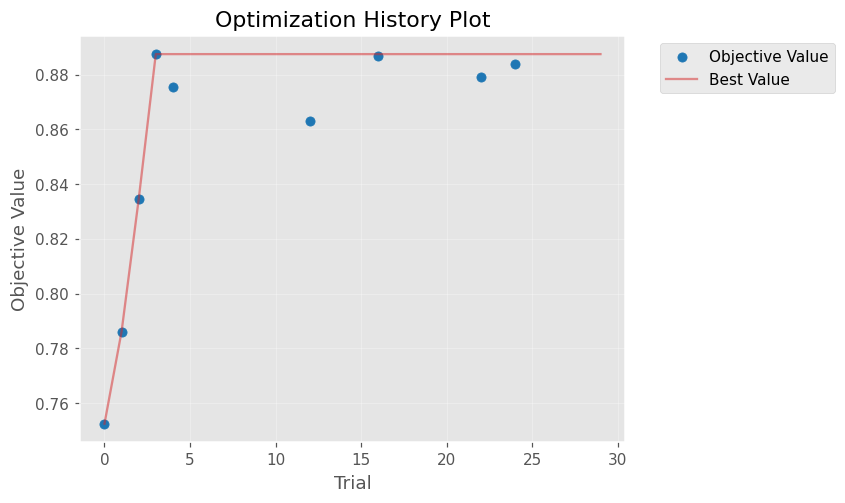

In [7]:
plot_optimization_history(study)
plt.show()

**Optimization history.** Each blue dot is one *completed* trial and its objective value – the best val macro-F1
reached within 10 epochs; the red line is the best value found so far. Pruned trials have no final objective value, so
they are not shown here (see the next subsection). The plot answers two questions: how quickly the search found a good
configuration and whether it was still improving when it stopped.

Here the best value (0.8875) was found already in trial 3 – still in TPE's random start-up phase – and the line stays flat
afterwards: the later, TPE-guided trials #16 (0.887), #24 (0.884) and #22 (0.879) came very close but did not beat it.
The search has therefore plateaued, so more trials with the same search space and budget would most likely bring little
improvement. The lowest point is trial 0, i.e. the baseline configuration (0.752).

### **Completed vs pruned trials**

COMPLETE: 9 trials


,number,value,epochs_reached,optimizer,lr_adamw,lr_sgd,scheduler,augment,width,batch_size,dropout,label_smoothing,weight_decay
0,3,0.8875,10,adamw,0.0087,NaN,onecycle,True,48,128,0.0610,0.0990,0.0001
1,16,0.8870,10,sgd,NaN,0.2778,onecycle,True,48,128,0.0437,0.0742,0.0000
2,24,0.8840,10,adamw,0.0040,NaN,onecycle,True,48,64,0.0785,0.1626,0.0000
3,22,0.8792,10,sgd,NaN,0.2960,onecycle,True,48,128,0.1138,0.0246,0.0000
4,4,0.8754,10,sgd,NaN,0.1531,onecycle,True,48,128,0.0980,0.0090,0.0000
5,12,0.8633,10,sgd,NaN,0.0847,cosine,True,48,128,0.0199,0.0145,0.0000
6,2,0.8345,10,adamw,0.0079,NaN,cosine,False,32,128,0.1832,0.0912,0.0000
7,1,0.7861,10,sgd,NaN,0.0281,none,True,32,128,0.0290,0.1732,0.0000
8,0,0.7524,10,adamw,0.0010,NaN,none,False,32,128,0.0000,0.0000,0.0000


PRUNED: 21 trials


,number,value,epochs_reached,optimizer,lr_adamw,lr_sgd,scheduler,augment,width,batch_size,dropout,label_smoothing,weight_decay
0,28,0.8678,10,sgd,NaN,0.0579,cosine,True,48,64,0.0653,0.1130,0.0000
1,8,0.8047,7,sgd,NaN,0.0300,none,False,64,64,0.2136,0.1636,0.0000
2,14,0.8026,7,adamw,0.0021,NaN,onecycle,False,48,128,0.0453,0.1616,0.0001
3,21,0.7683,6,sgd,NaN,0.1388,onecycle,False,48,128,0.0113,0.0556,0.0000
4,29,0.7544,4,adamw,0.0039,NaN,onecycle,True,48,64,0.0182,0.1409,0.0001
5,26,0.7444,4,adamw,0.0094,NaN,cosine,True,48,128,0.0131,0.1424,0.0009
6,9,0.7379,4,sgd,NaN,0.0164,cosine,False,48,64,0.2486,0.0602,0.0000
7,17,0.7332,4,sgd,NaN,0.2797,onecycle,True,48,256,0.1447,0.1007,0.0002
8,25,0.7312,4,adamw,0.0041,NaN,onecycle,True,48,64,0.1026,0.1466,0.0000
9,10,0.7300,4,adamw,0.0098,NaN,onecycle,True,48,128,0.1811,0.0449,0.0014


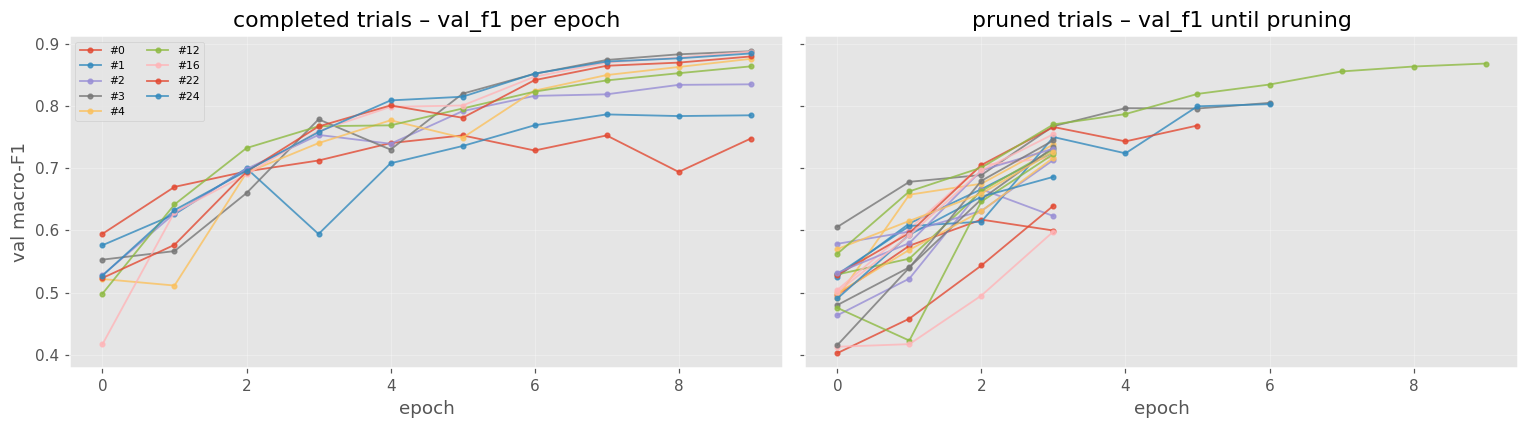

In [8]:
epochs_reached = {t.number: len(t.intermediate_values) for t in study.trials}
tdf["epochs_reached"] = tdf["number"].map(epochs_reached)
param_cols = ["optimizer", "lr_adamw", "lr_sgd", "scheduler", "augment", "width", "batch_size", "dropout", "label_smoothing", "weight_decay"]

for state in ["COMPLETE", "PRUNED"]:
    sub = tdf[tdf.state == state].sort_values("value", ascending=False)
    print(f"{state}: {len(sub)} trials")
    display(sub[["number", "value", "epochs_reached"] + param_cols].round(4).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for t in study.trials:
    if not t.intermediate_values:
        continue
    x, y = zip(*sorted(t.intermediate_values.items()))
    a = ax[0] if t.state.name == "COMPLETE" else ax[1]
    a.plot(x, y, "-", alpha=0.8, lw=1.2, marker=".", label=f"#{t.number}" if t.state.name == "COMPLETE" else None)
ax[0].set_title("completed trials – val_f1 per epoch"); ax[0].legend(fontsize=7, ncol=2)
ax[1].set_title("pruned trials – val_f1 until pruning")
for a in ax: a.set_xlabel("epoch")
ax[0].set_ylabel("val macro-F1"); plt.tight_layout(); plt.show()

21 of 30 trials were pruned, most of them after 4 epochs (the earliest point allowed by `n_warmup_steps=3`), which
roughly halved the cost of the search (~60 min in total instead of ~100 min for 30 full trials). All completed trials except the
baseline (#0) and #1 end above 0.83, and the five best ones (> 0.87) all use `onecycle` and augmentation. Trial #28 was pruned
only at its last epoch with val macro-F1 0.868 – a run that was competitive but still below the median of the earlier trials.

### **Hyperparameter importance (fANOVA)**

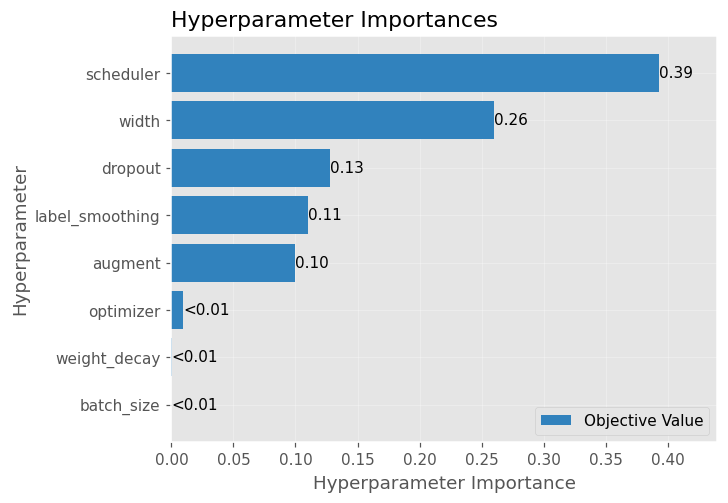

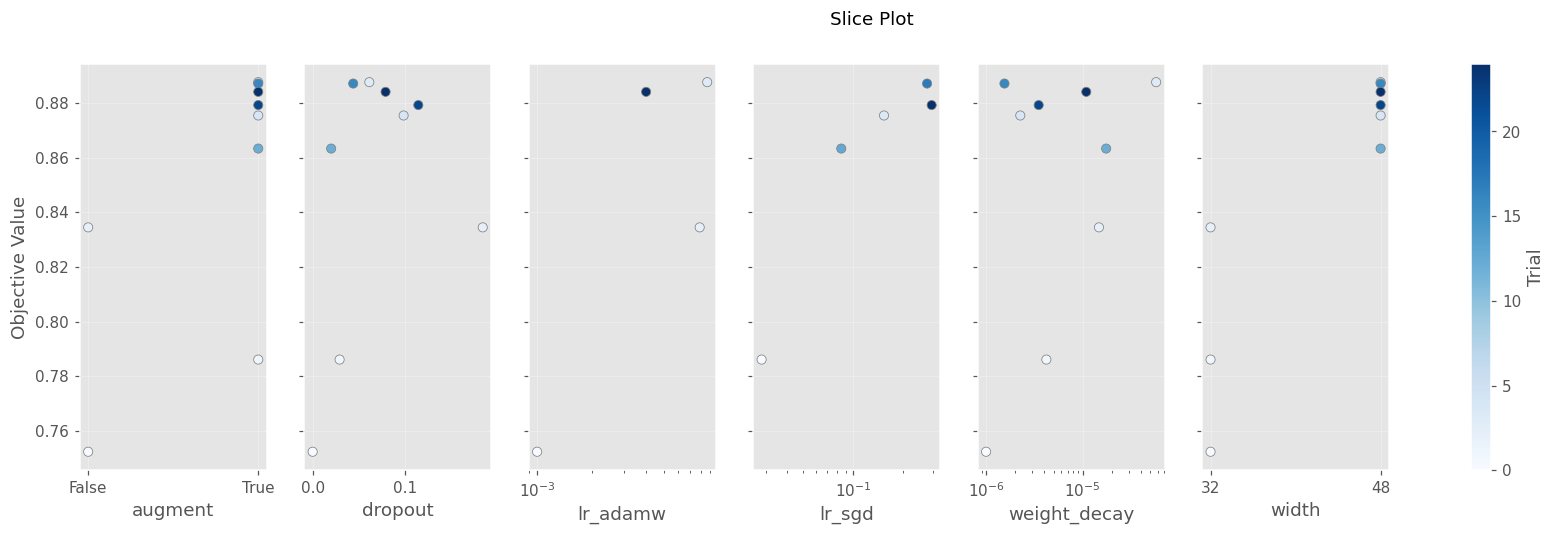

In [9]:
plot_param_importances(study)
plt.show()

plot_slice(study, params=["lr_adamw", "lr_sgd", "weight_decay", "dropout", "augment", "width"])
plt.show()

**Does the most important parameter match the intuition?** Only partly. fANOVA ranks *scheduler* (0.39) and *width* (0.26) highest, followed by *dropout* (0.13), *label_smoothing* (0.11) and *augment* (0.10); *optimizer*, *batch_size* and *weight_decay* come out at ~0. Beforehand we expected *augment* and *lr* to dominate.
* *scheduler* being near the top is plausible: every completed trial with val macro-F1 > 0.87 uses *onecycle* –
  with a 10-epoch budget, annealing the LR to ~0 at the end gives a large boost.
* *augment* matters, but less than expected – mostly because almost all later (TPE-guided) trials already use it,
  so there is little variance left for it to explain.
* *lr* does not appear at all: it is split into the conditional parameters *lr_adamw* / *lr_sgd*, which exist only in
  a subset of trials, while the importance evaluator only uses parameters present in every trial.
* Caveat: importances are computed from only the 9 completed trials (21 were pruned), so they are noisy.

### **Parallel coordinates (MLflow)**

Comparison of all 30 runs of the `cifar10-optuna` experiment in the MLflow UI. Each line is one trial and each vertical axis one hyperparameter. The last two axes are the metrics, and the colour of the line encodes `val_loss` (blue = low = good, red = high = bad). Unlike the importance plot, this view shows which *combinations* of values lead to good trials. Unlike Optuna's version, it also includes the pruned trials and shows the learning rate on a single `lr` axis for both optimizers.

![MLflow parallel coordinates of the Optuna trials](../results/mlflow/optuna_comparison.png)

**What the plot shows.**
* **Good trials (dark blue, val_loss < 0.5, val macro-F1 > 0.86).** All seven trials with the lowest val loss share
  `augment = True`, `width = 48`, batch size 128 or 64, an annealed LR (`onecycle` or `cosine`) and a small weight decay (≤ 6e-5).
  Both optimizers appear among them, SGD with a high LR (0.15–0.30) and AdamW with LR ≈ 4e-3–9e-3, which is consistent with
  the low importance of `optimizer` once its LR is in the right range.
* **Bad trials (red, val_loss > 1.0).** The four worst runs (#5, #7, #13, #20) were all pruned after 4 epochs. Three of
  them have no augmentation, two use batch size 256 and two have the largest weight decay (~1e-3–2e-3). The fourth (#13)
  is AdamW with a very small LR (1.3e-4), which learns too slowly.
* **Caveat.** MLflow shows the *last* logged value of each metric. For most pruned trials this is the value after only 4 epochs
  (a few after 6–7, #28 after 10), while completed trials are shown after 10 epochs, so part of the colour difference simply reflects how long a trial ran.

### **Worst run**

Worst completed trial:
number                                  0
value                            0.752429
state                            COMPLETE
augment                             False
batch_size                            128
dropout                               0.0
label_smoothing                       0.0
lr_adamw                            0.001
optimizer                           adamw
scheduler                            none
weight_decay                     0.000001
width                                  32
best_epoch                            5.0
run_name                        trial_000
train_time_s                   102.902513
duration           0 days 00:01:43.435805
epochs_reached                         10

21 pruned trials, e.g.:


,number,value,state,augment,batch_size,dropout,label_smoothing,lr_adamw,lr_sgd,optimizer,scheduler,weight_decay,width,best_epoch,run_name,train_time_s,duration,epochs_reached
5,5,0.599685,PRUNED,False,256,0.353429,0.145801,NaN,0.028798,sgd,none,0.001827,32,NaN,NaN,NaN,0 days 00:00:39.237137,4
6,6,0.725188,PRUNED,True,128,0.356622,0.152157,NaN,0.087107,sgd,cosine,0.000003,48,NaN,NaN,NaN,0 days 00:01:20.882179,4
7,7,0.622892,PRUNED,False,64,0.114399,0.015396,NaN,0.208170,sgd,none,0.001052,32,NaN,NaN,NaN,0 days 00:00:48.454035,4
8,8,0.804651,PRUNED,False,64,0.213554,0.163603,NaN,0.030020,sgd,none,0.000008,64,NaN,NaN,NaN,0 days 00:03:17.631577,7
9,9,0.737889,PRUNED,False,64,0.248624,0.060176,NaN,0.016369,sgd,cosine,0.000010,48,NaN,NaN,NaN,0 days 00:01:29.636314,4


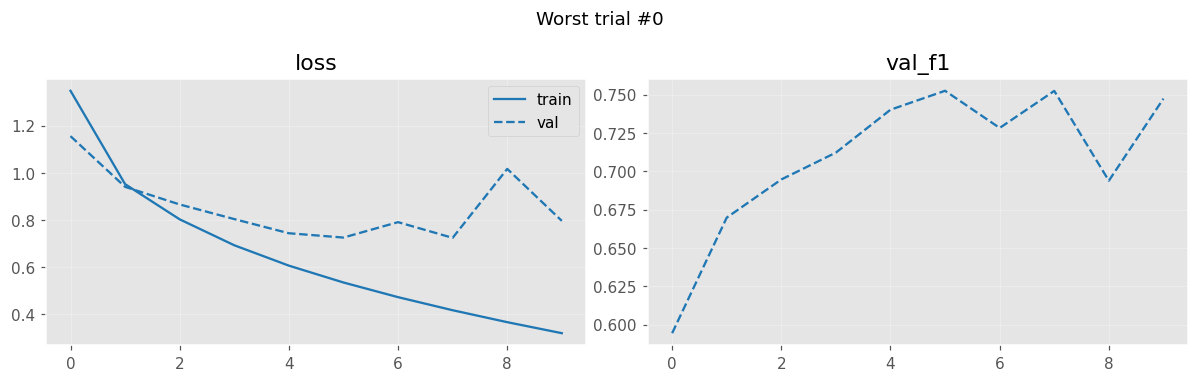

In [11]:
complete = tdf[tdf.state == "COMPLETE"]
worst = complete.sort_values("value").iloc[0]
print("Worst completed trial:", worst.dropna().to_string(), sep="\n")
pruned = tdf[tdf.state == "PRUNED"]
print(f"\n{len(pruned)} pruned trials, e.g.:")
display(pruned.head(5))

wdf = pd.read_csv(RUNS_DIR / worst["run_name"] / "metrics.csv").groupby("epoch").first().dropna(subset=["train_loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(wdf.index, wdf.train_loss, "-", color="tab:blue", label="train"); ax[0].plot(wdf.index, wdf.val_loss, "--", color="tab:blue", label="val"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(wdf.index, wdf.val_f1, "--", color="tab:blue"); ax[1].set_title("val_f1")
fig.suptitle(f"Worst trial #{int(worst.number)}"); plt.tight_layout(); plt.show()

* Among *completed* trials the worst one is trial #0 – the baseline configuration itself (val macro-F1 0.752 after
  10 epochs): no augmentation, no regularisation, constant LR. Its curves show the same pattern as the full baseline run:
  train loss keeps falling while val loss stops improving after ~5 epochs. Every other completed trial beat it.
* The worst trials overall were pruned: #20 (val macro-F1 0.598 when stopped after 4 epochs) and #5 (0.600). Both use
  SGD with a small LR (0.01–0.03) and batch size 256, i.e. few and small update steps per epoch, so they learn slowly;
  they were far below the median and the pruner stopped them early.
* A side effect of pruning: `onecycle` warms the LR up during the first 30% of training, so at epoch 3–4 such runs
  can look worse than runs with a constant LR. Several `onecycle` trials (e.g. #10, #19, #25, #29) were pruned early
  even though `onecycle` turned out to be the best scheduler – the MedianPruner compares runs at the same epoch, which
  is biased against schedules that pay off late.

## **5. Comparison: baseline vs manual fix vs best (after hyperparameter optimization)**

In [12]:
best_params = yaml.safe_load((RESULTS_DIR / "best_params.yaml").read_text())
print("Best params from Optuna:", best_params)

rows = []
for n, (_, s) in runs.items():
    rows.append({"run": n, "val_acc": s["val"]["val_acc"], "val_f1": s["val"]["val_f1"],
                 "test_acc": s["test"]["test_acc"], "test_f1": s["test"]["test_f1"],
                 "best_epoch": s["best_epoch"], "params": s["n_params"], "train_time_min": s["train_time_s"] / 60})
cmp = pd.DataFrame(rows).set_index("run")
base = cmp.loc["baseline"]
for m in ["val_f1", "test_f1"]:
    cmp[f"{m} Δ pp"] = (cmp[m] - base[m]) * 100
    cmp[f"{m} Δ rel %"] = (cmp[m] / base[m] - 1) * 100
display(cmp.round(4))

if "best" in cmp.index:
    d_pp, d_rel = cmp.loc["best", "val_f1 Δ pp"], cmp.loc["best", "val_f1 Δ rel %"]
    print(f"Hyperparameter optimization improvement on validation macro-F1: {d_pp:+.2f} pp ({d_rel:+.2f}% relative) -> "
          f"criterion >= 3%: {'MET' if d_pp >= 3 else 'NOT met'}")

Best params from Optuna: {'augment': True, 'batch_size': 128, 'dropout': 0.06101911742238941, 'label_smoothing': 0.09903538202225404, 'lr': 0.00869299151113955, 'optimizer': 'adamw', 'scheduler': 'onecycle', 'weight_decay': 5.762487216478604e-05, 'width': 48}


,val_acc,val_f1,test_acc,test_f1,best_epoch,params,train_time_min,val_f1 Δ pp,val_f1 Δ rel %,test_f1 Δ pp,test_f1 Δ rel %
run,,,,,,,,,,,
baseline,0.7780,0.7788,0.7786,0.7793,11,308650,3.4313,0.0000,0.0000,0.0000,0.0000
manual_fix,0.8642,0.8644,0.8548,0.8546,17,308650,3.4808,8.5596,10.9901,7.5285,9.6607
best,0.9090,0.9092,0.9073,0.9072,19,691834,7.6111,13.0371,16.7389,12.7863,16.4075


Hyperparameter optimization improvement on validation macro-F1: +13.04 pp (+16.74% relative) -> criterion >= 3%: MET


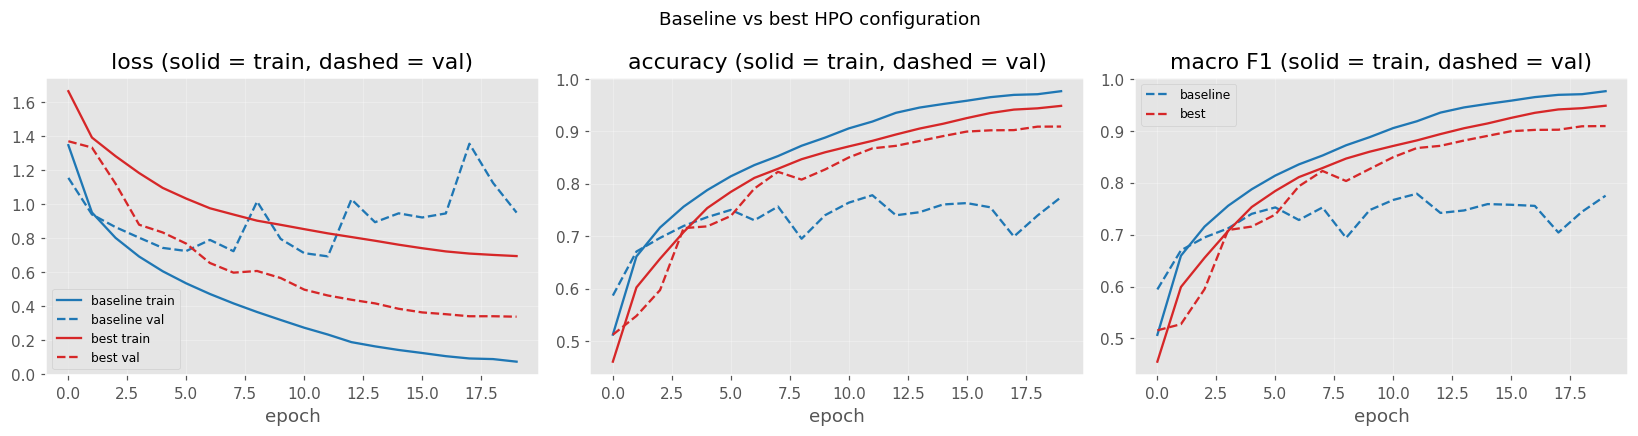

In [13]:
if "best" in runs:
    plot_curves(["baseline", "best"], "Baseline vs best HPO configuration")

#### **Results** 
Hyperparameter optimization improves validation macro-F1 from 0.779 to 0.909 (+13.0 pp, +16.7% relative) and
test macro-F1 from 0.779 to 0.907 (+12.8 pp) → the **≥ 3% criterion is met** with a large margin. The gain on the untouched
test set is practically the same as on validation, so it is not an artefact of selecting hyperparameters on the val set.
* **Best configuration:** AdamW, lr ≈ 8.7e-3, OneCycle, augmentation, width 48 (692k parameters, 2.2× the baseline),
  label smoothing ≈ 0.10, dropout ≈ 0.06, weight decay ≈ 6e-5, batch size 128. It was found as trial #3 – one of TPE's
  initial random trials – and the later TPE-guided trials (e.g. #16: 0.887, #24: 0.884) only matched it.
* **Train loss above val loss** in the `best` curves (0.70 vs 0.34) is not underfitting: label smoothing makes the minimum
  attainable train loss > 0 and the training images are augmented (harder), while val loss is computed on clean images
  without smoothing. Train vs val accuracy (94.8% vs 90.9%) is the fair comparison here.
* **Cost:** an epoch of `best` takes ~23 s vs ~10 s for the baseline (wider network).

## **6. Error analysis of the best model (test set)**

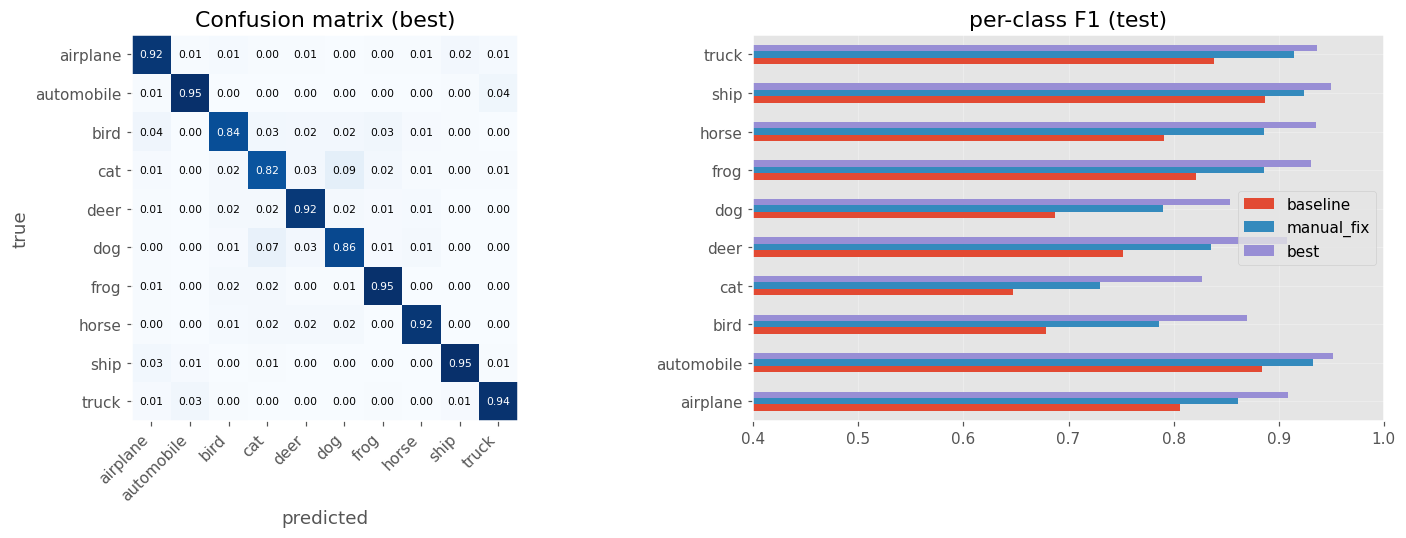

Most frequent confusions (true -> predicted):
         cat -> dog        86
         dog -> cat        73
        bird -> airplane   39
  automobile -> truck      35
       truck -> automobile 33


In [14]:
name = "best" if "best" in runs else "baseline"
cm = np.load(RUNS_DIR / name / "test_confusion_matrix.npy")
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax[0].imshow(cmn, cmap="Blues")
ax[0].set_xticks(range(10), CLASSES, rotation=45, ha="right"); ax[0].set_yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i,j] > .5 else "black")
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title(f"Confusion matrix ({name})"); ax[0].grid(False)
pcf = pd.DataFrame({n: s["test_per_class_f1"] for n, (_, s) in runs.items()}, index=CLASSES)
pcf.plot.barh(ax=ax[1]); ax[1].set_title("per-class F1 (test)"); ax[1].set_xlim(0.4, 1)
plt.tight_layout(); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print("Most frequent confusions (true -> predicted):")
for i, j in top: print(f"  {CLASSES[i]:>10s} -> {CLASSES[j]:<10s} {off[i,j]}")

The hardest classes are the same for all three models: `cat` (F1 0.648 → 0.827) and `dog` (0.687 → 0.854), followed by `bird`. The most frequent confusions are `cat` ↔ `dog` (86 + 73 test images), `bird` → `airplane` and `automobile` ↔ `truck` – visually similar classes at 32×32 resolution. HPO improved every class, and the weakest classes gained the most (bird +19.2 pp, cat +17.9 pp), so the improvement is not achieved at the expense of any class.

## **7. Monitoring in MLflow**

All runs (baseline, manual_fix, best and every Optuna trial) are logged with
`lightning.pytorch.loggers.MLFlowLogger` to the local `mlruns/` directory. To browse the curves and compare runs:

```bash
cd lab1 && source .venv/bin/activate
mlflow ui --backend-store-uri ./mlruns    # http://127.0.0.1:5000
```

Below, the same curves were read directly from MLflow (proof that logging works).

### **Baseline:** `train_loss` vs `val_loss`

![baseline loss](../results/mlflow/baseline_loss.png)

### **Comparison** of the baseline / manual_fix / best runs — `val_f1`, `val_loss`:

Screenshots from the MLflow UI: `val_f1` (top row) and `val_loss` (bottom row) of the three runs.

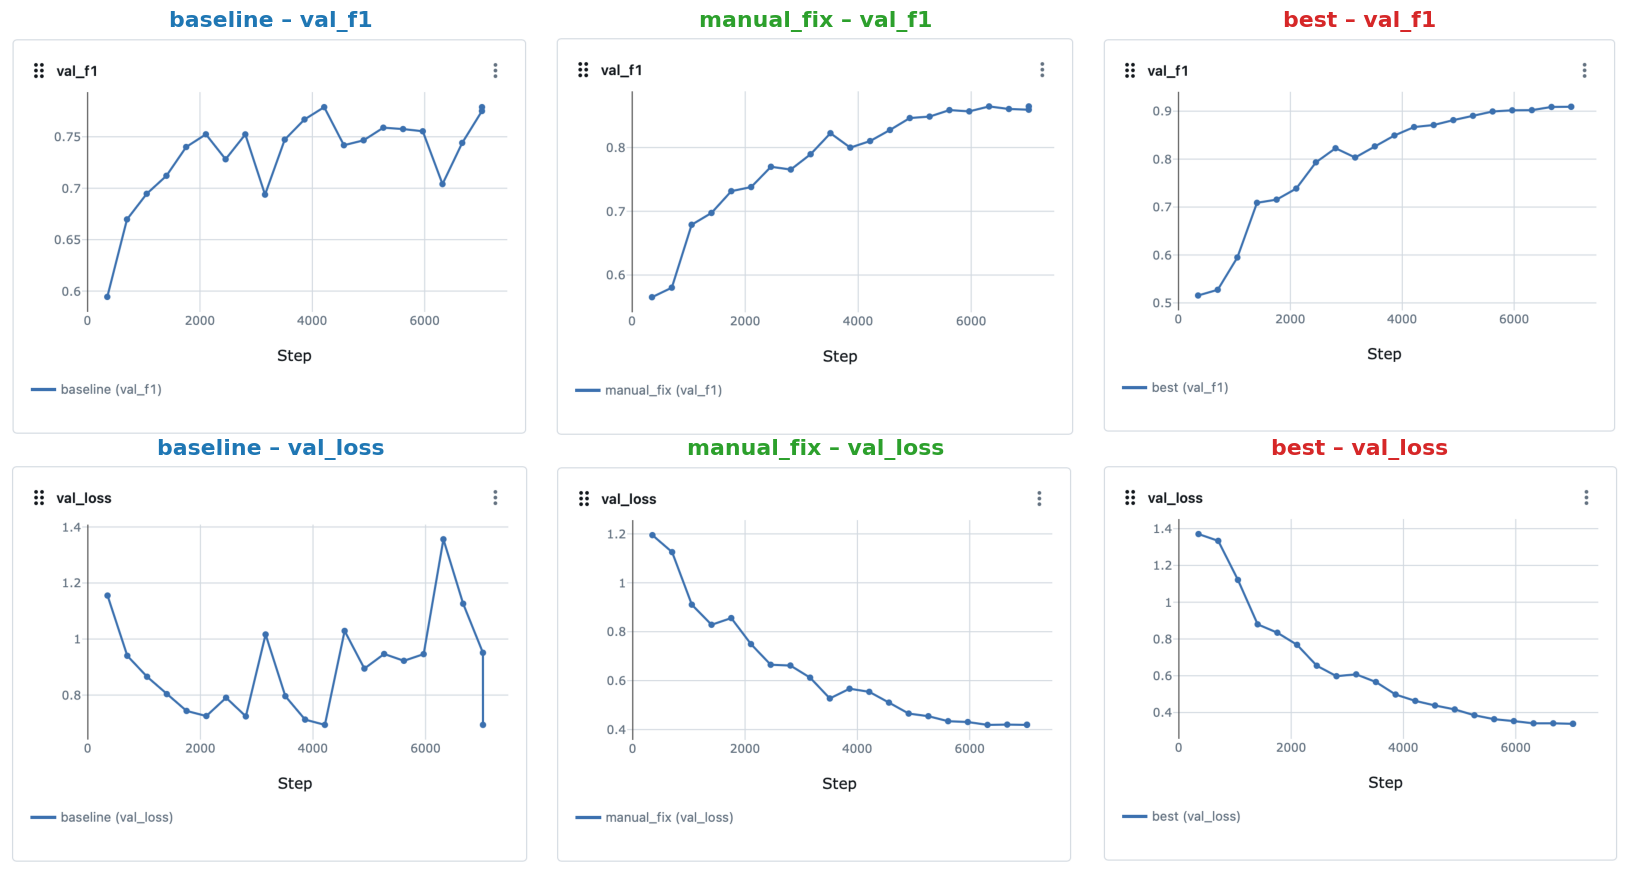

In [15]:
shots_dir = ROOT / "results" / "mlflow"
run_files = {"baseline": "baseline", "manual_fix": "mf", "best": "best"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, (run, suffix) in enumerate(run_files.items()):
    for row, metric in enumerate(["val_f1", "val_loss"]):
        ax = axes[row, col]
        ax.imshow(plt.imread(shots_dir / f"{metric}_{suffix}.png"))
        ax.set_title(f"{run} – {metric}", color=RUN_COLORS[run], fontweight="bold")
        ax.axis("off")
plt.tight_layout(); plt.show()

### **Optuna trials** – `val_f1` per epoch:

<!-- ![optuna trials](../results/mlflow/optuna_trials.png) -->

experiment 'cifar10': 3 runs


experiment 'cifar10-optuna': 30 runs


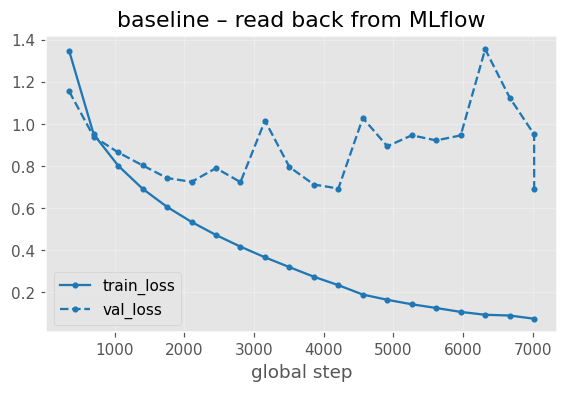

In [16]:
client = mlflow.tracking.MlflowClient(tracking_uri=MLFLOW_URI)
for exp_name in ["cifar10", "cifar10-optuna"]:
    exp = client.get_experiment_by_name(exp_name)
    if exp:
        n = len(client.search_runs([exp.experiment_id], max_results=1000))
        print(f"experiment {exp_name!r}: {n} runs")

rid = runs["baseline"][1]["mlflow_run_id"]
fig, ax = plt.subplots(figsize=(6, 3.5))
for key, style in [("train_loss", "-"), ("val_loss", "--")]:
    h = client.get_metric_history(rid, key)
    ax.plot([m.step for m in h], [m.value for m in h], style, color="tab:blue", marker=".", label=key)
ax.set_xlabel("global step"); ax.set_title("baseline – read back from MLflow"); ax.legend(); plt.show()

The curves read back from MLflow are identical to the CSV-based plots in section 2, which confirms that both loggers
record the same values. The last `val_loss` point drops vertically from 0.95 to 0.69 (also visible in the MLflow screenshot):
this is not part of training – after `fit()` the script re-validates the **best checkpoint** (epoch 11) and that value is logged
at the same final step.

## **8. Conclusions**

* **Change based on the curves:** the baseline overfitted strongly (train accuracy 97.6% vs val 77.4%, unstable and rising val loss). Adding augmentation, weight decay and a cosine LR schedule (`manual_fix`) closed the gap to 2 pp and raised val macro-F1 by 8.5 pp (0.779 → 0.864).
* **What HPO achieved and which parameters mattered most:** another +4.5 pp on top of `manual_fix` and +13.0 pp over the baseline (val macro-F1 0.909, test 0.907). The most important parameters were the network width, the LR schedule (OneCycle) and augmentation; batch size and weight decay hardly mattered in this search space.
* **Main problems:**
  * slow download of the dataset from the CIFAR server (tens of minutes);
  * a callback-ordering bug: Lightning calls `Callback.on_validation_epoch_end` *before* the LightningModule's hook, so a callback reading `trainer.callback_metrics` there sees the previous epoch's value – fixed by using `on_validation_end`;
  * compute budget: 30 trials × 10 epochs take ~1 h on Apple MPS, so trials use half of the final epoch budget and rely on pruning (21/30 pruned) – at the cost of a bias against slow-starting schedules (OneCycle) and a mismatch between trial (10) and final (20) epochs for epoch-dependent schedulers;
  * `run_all.sh` failed on macOS: bash 3.2 with `set -u` treats an empty array as an unbound variable.
* **One-sentence takeaway:** look at the train/val curves before tuning anything – the biggest single gain came from fixing the overfitting they revealed, and hyperparameter oprimization then works much better in a search space that already contains the right regularisers.